# Lab 6 — Reinforcement learning

Learn a policy by interacting, then save it.

## Setup

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

PROJECT_ROOT = Path.cwd().parent
MODELS = PROJECT_ROOT / "models"
MODELS.mkdir(exist_ok=True)

## Part A — Tabular Q-learning in a 4×4 GridWorld

In [2]:
rng = np.random.default_rng(42)

ROWS, COLS = 4, 4
START, GOAL, TRAP = (0, 0), (3, 3), (1, 3)
ACTIONS = [(-1, 0), (1, 0), (0, -1), (0, 1)]        # up, down, left, right
ACTION_NAMES = ["up", "down", "left", "right"]
ARROWS = {"up": (0, 1), "down": (0, -1), "left": (-1, 0), "right": (1, 0)}

def step(state, action):
    """Apply one action. Returns (next_state, reward, done)."""
    r, c = state
    dr, dc = ACTIONS[action]
    next_state = (min(max(r + dr, 0), ROWS - 1), min(max(c + dc, 0), COLS - 1))
    if next_state == GOAL:
        return next_state, 1.0, True
    if next_state == TRAP:
        return next_state, -1.0, True
    return next_state, -0.04, False

In [3]:
Q = np.zeros((ROWS, COLS, len(ACTIONS)))
alpha, gamma = 0.15, 0.95
epsilon, min_epsilon = 1.0, 0.05

def choose_action(state, explore=True):
    if explore and rng.random() < epsilon:
        return int(rng.integers(len(ACTIONS)))       # explore: random move
    return int(np.argmax(Q[state]))                  # exploit: best known move

training_returns = []
for episode in range(5000):
    state, episode_return = START, 0.0
    for _ in range(100):
        action = choose_action(state)
        next_state, reward, done = step(state, action)
        episode_return += reward
        target = reward if done else reward + gamma * np.max(Q[next_state])
        Q[state][action] += alpha * (target - Q[state][action])
        state = next_state
        if done:
            break
    training_returns.append(episode_return)
    epsilon = max(min_epsilon, epsilon * 0.9985)

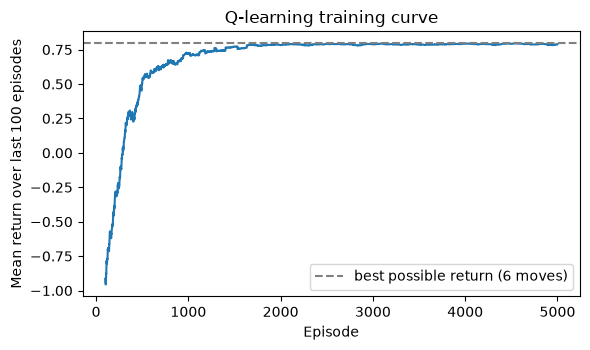

In [4]:
window = 100
moving = np.convolve(training_returns, np.ones(window) / window, mode="valid")
plt.figure(figsize=(6, 3.6))
plt.plot(np.arange(window - 1, len(training_returns)), moving)
plt.axhline(0.8, linestyle="--", color="grey", label="best possible return (6 moves)")
plt.xlabel("Episode")
plt.ylabel("Mean return over last 100 episodes")
plt.title("Q-learning training curve")
plt.legend()
plt.tight_layout()
plt.show()

In [5]:
successes, returns = 0, []
for _ in range(200):
    state, total = START, 0.0
    for _ in range(100):
        state, reward, done = step(state, choose_action(state, explore=False))
        total += reward
        if done:
            successes += int(state == GOAL)
            break
    returns.append(total)

print("success rate:", successes / 200)
print("mean return:", round(float(np.mean(returns)), 3))
print("learned action at start:", ACTION_NAMES[choose_action(START, explore=False)])

success rate: 1.0
mean return: 0.8
learned action at start: down


## Part B — The Q-table is the model: save it and read the policy

In [6]:
q_path = MODELS / "gridworld_q_table.npy"
np.save(q_path, Q)

Q_loaded = np.load(q_path)
policy = np.full((ROWS, COLS), "", dtype=object)
for r in range(ROWS):
    for c in range(COLS):
        policy[r, c] = "GOAL" if (r, c) == GOAL else "TRAP" if (r, c) == TRAP \
            else ACTION_NAMES[int(np.argmax(Q_loaded[r, c]))]
print(policy)

[['down' 'down' 'down' 'left']
 ['down' 'down' 'down' 'TRAP']
 ['right' 'down' 'down' 'down']
 ['right' 'right' 'right' 'GOAL']]


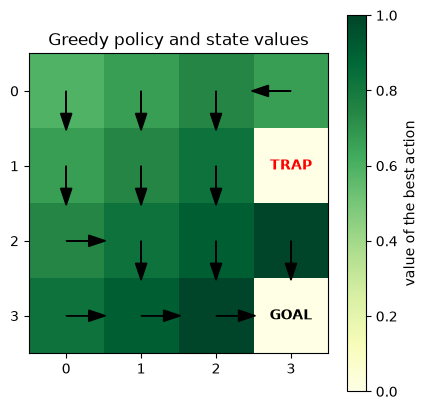

In [7]:
def plot_policy(Q_table, title):
    values = Q_table.max(axis=2)
    plt.figure(figsize=(4.4, 4.2))
    plt.imshow(values, cmap="YlGn")
    plt.colorbar(label="value of the best action")
    for r in range(ROWS):
        for c in range(COLS):
            if (r, c) == GOAL:
                plt.text(c, r, "GOAL", ha="center", va="center", fontweight="bold")
            elif (r, c) == TRAP:
                plt.text(c, r, "TRAP", ha="center", va="center", color="red", fontweight="bold")
            else:
                dx, dy = ARROWS[ACTION_NAMES[int(np.argmax(Q_table[r, c]))]]
                plt.arrow(c, r, 0.3 * dx, -0.3 * dy, head_width=0.15, color="black")
    plt.xticks(range(COLS))
    plt.yticks(range(ROWS))
    plt.title(title)
    plt.tight_layout()
    plt.show()

plot_policy(Q_loaded, "Greedy policy and state values")

## Try it yourself

In [8]:
def train_q_learning(step_cost=-0.04, trap=(1, 3), gamma=0.95, decay=0.9985,
                     episodes=5000, seed=42):
    """Same Q-learning as Part A, with the settings as arguments."""
    local_rng = np.random.default_rng(seed)

    def env_step(state, action):
        r, c = state
        dr, dc = ACTIONS[action]
        nxt = (min(max(r + dr, 0), ROWS - 1), min(max(c + dc, 0), COLS - 1))
        if nxt == GOAL:
            return nxt, 1.0, True
        if nxt == trap:
            return nxt, -1.0, True
        return nxt, step_cost, False

    Q_new = np.zeros((ROWS, COLS, len(ACTIONS)))
    eps = 1.0
    for _ in range(episodes):
        state = START
        for _ in range(100):
            if local_rng.random() < eps:
                action = int(local_rng.integers(len(ACTIONS)))
            else:
                action = int(np.argmax(Q_new[state]))
            nxt, reward, done = env_step(state, action)
            target = reward if done else reward + gamma * np.max(Q_new[nxt])
            Q_new[state][action] += alpha * (target - Q_new[state][action])
            state = nxt
            if done:
                break
        eps = max(min_epsilon, eps * decay)

    # Greedy evaluation from the start
    state, total, path = START, 0.0, [START]
    for _ in range(100):
        state, reward, done = env_step(state, int(np.argmax(Q_new[state])))
        total += reward
        path.append(state)
        if done:
            break
    return Q_new, state == GOAL, len(path) - 1, round(total, 3)


def show_policy(Q_table, trap):
    grid = np.full((ROWS, COLS), "", dtype=object)
    for r in range(ROWS):
        for c in range(COLS):
            grid[r, c] = "GOAL" if (r, c) == GOAL else "TRAP" if (r, c) == trap \
                else ACTION_NAMES[int(np.argmax(Q_table[r, c]))]
    print(grid)

**Experiment 1 — expensive steps (step cost −0.04 → −1.5).**

Prediction: the goal is 6 moves away, so reaching it now returns 5 × (−1.5) + 1 = −6.5. The trap is only 4 moves away, returning 3 × (−1.5) − 1 = −5.5. Ending the episode in the trap is now less bad than walking to the goal, so the agent should head straight for the trap.

reached goal: False  moves: 4  return: -5.5
[['down' 'down' 'down' 'down']
 ['right' 'right' 'right' 'TRAP']
 ['right' 'down' 'down' 'down']
 ['right' 'right' 'right' 'GOAL']]


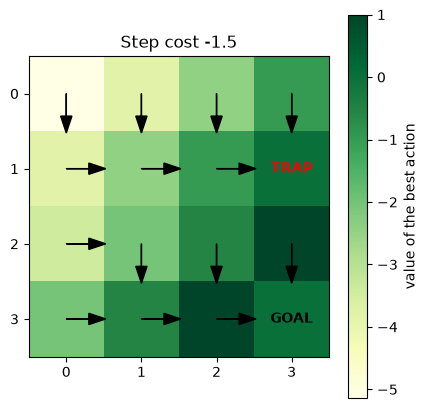

In [9]:
Q_costly, reached_goal, moves, ret = train_q_learning(step_cost=-1.5)
print("reached goal:", reached_goal, " moves:", moves, " return:", ret)
show_policy(Q_costly, TRAP)
plot_policy(Q_costly, "Step cost -1.5")

**Experiment 2 — free steps and no discount pressure (step cost 0, γ = 0.99).**

Prediction: moving costs nothing, so the only pressure to be quick is the discount. Because γ = 0.99 is still below 1, a reward reached sooner is worth slightly more, so the agent should still take a shortest 6-move route and avoid the trap. The return should be exactly 1.0, since no step costs are subtracted.

reached goal: True  moves: 6  return: 1.0
[['down' 'down' 'down' 'left']
 ['down' 'down' 'down' 'TRAP']
 ['right' 'down' 'down' 'down']
 ['right' 'right' 'right' 'GOAL']]


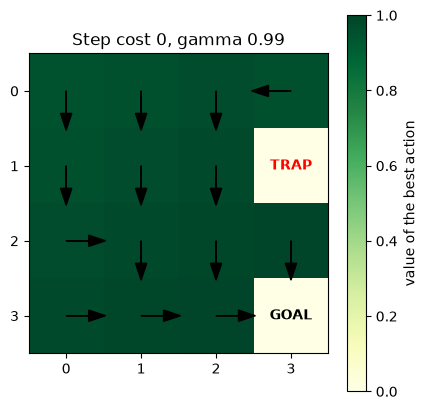

In [10]:
Q_free, reached_goal, moves, ret = train_q_learning(step_cost=0.0, gamma=0.99)
print("reached goal:", reached_goal, " moves:", moves, " return:", ret)
show_policy(Q_free, TRAP)
plot_policy(Q_free, "Step cost 0, gamma 0.99")

**Experiment 3 — move the trap to (2, 2), right on the diagonal.**

Prediction: the shortest routes along the middle of the grid are now blocked, so the agent should go around the trap along an edge. The shortest safe path is still 6 moves, so the return should stay 0.80.

reached goal: True  moves: 6  return: 0.8
[['right' 'right' 'right' 'down']
 ['right' 'right' 'right' 'down']
 ['down' 'down' 'TRAP' 'down']
 ['right' 'right' 'right' 'GOAL']]


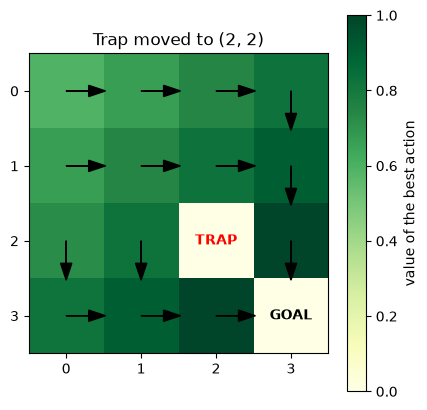

In [11]:
TRAP_ORIGINAL = TRAP
Q_moved, reached_goal, moves, ret = train_q_learning(trap=(2, 2))
print("reached goal:", reached_goal, " moves:", moves, " return:", ret)
show_policy(Q_moved, (2, 2))
TRAP = (2, 2)                 # plot_policy reads the global TRAP
plot_policy(Q_moved, "Trap moved to (2, 2)")
TRAP = TRAP_ORIGINAL

**What happened.**

| Change | Predicted | Result |
| --- | --- | --- |
| Step cost −1.5 | Agent heads for the trap | Correct: it walks right along row 1 into the trap in 4 moves, return −5.5 (better than −6.5 via the goal) |
| Step cost 0, γ = 0.99 | Still a 6-move route to the goal, return 1.0 | Correct: same policy as Part A, 6 moves, return 1.0 |
| Trap moved to (2, 2) | Agent goes around the trap, still 6 moves, return 0.80 | Correct: it goes right along the top row and down the right edge, 6 moves, return 0.80 |

The policy depends entirely on the rewards. When moving becomes very expensive, ending the episode early in the trap is the "best" choice, which is rational for the reward but clearly not what a designer would want. Reward design has to make the intended behaviour the one with the highest return. The discount factor alone is enough to make the agent prefer short routes, even with no step cost. Moving the trap changes the route but not its length, because a 6-move path around the trap still exists.

## Check your understanding

**1. What are the state, action, reward, and transition in a reinforcement-learning formulation?**

The **state** is the situation the agent is in, here its (row, column) cell on the grid. An **action** is a choice the agent can make in that state, here up, down, left or right. The **reward** is the number the environment gives back after an action, here −0.04 for an ordinary move, +1 for reaching the goal and −1 for the trap. The **transition** is the rule that decides the next state from the current state and action; in this GridWorld it is the `step` function, which moves one cell and keeps the agent in place at a wall.

**2. What two pieces of information appear in the tabular Q-learning backup value?**

The backup target is r + γ · max over a′ of Q(s′, a′). It combines the **immediate reward** r received for the action just taken, and the **discounted estimate of the best future value** from the next state s′, read from the current Q-table. The Q-value is then moved a fraction α of the way towards that target. When the episode ends (goal or trap) there is no future, so the target is just the reward.

**3. Why should the exploratory training policy be evaluated separately from the final greedy policy?**

During training the agent follows an ε-greedy policy, so it deliberately takes random actions some of the time to discover better routes. Those random moves sometimes walk into the trap or wander, so the training returns underestimate how good the learned policy really is, and they also mix in early episodes from before learning finished. The policy that will actually be used is the greedy one (always take the highest-Q action). Evaluating it separately with exploration turned off, as in Part A, measures the real performance: here a 100% success rate with return 0.80, the shortest route.